# E/I modularity with W_out frozen (150k)

The analysis of `ei_modularity_150k.ipynb` (W_out trained), on every 150k network with **W_out frozen** at its
fanin init that has saved weights: 8 budgets × 2 seeds. Question: does freezing the readout change the kind of
modularity (type 1 shared inhibition / type 2 mixed E+I modules / type 3 inhibition between modules)?

| group | point (run) | rate budget | wiring budget |
|---|---|---|---|
| control | control (rate ray) | none | none |
| rate only | A0 (rate ray) | 0.017 | free |
| rate only | hi0 (edge30) | 0.018 | 0.040 (barely binds) |
| wiring only | B0 (wiring ray) | free | 0.0054 |
| wiring only | hi9 (edge30) | 4.0 (barely binds) | 0.0061 |
| wiring only | r2w2 (grid) | 1.7 (barely binds) | 0.0054 |
| both | hi5 (edge30) | 0.34 | 0.0125 |
| both | r6w1 (grid) | 0.043 | 0.0134 |

Caveats up front: with W_out frozen, budgets as tight as the trained set's A3 / C0 do not train, so the "rate only"
and "both" budgets here are 10-30× looser; only 2 seeds per point; r6w1 seed 0 fails the tasks (0.48).

Extra check for this set (section 4): with a fixed random readout, E neurons that drive the same output must fire
together, so task-variance groups could partly just mirror the readout. We test whether E groups share readout
weights more than chance.

In [1]:
import contextlib, io
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import generate_trials, rule_name
from cmc.train_cog import (batch_accuracy, eval_config_from, load_checkpoint, response_mask, ring_prefs,
                           trial_to_tensors)

RUN = MOO_ZOOM_RUNS_DIR / "dale_all_rateray_woutfrozen_150k"
NETS = {
    "control": RUN / "control" / "seed_01.pt",
    "rate-limited (A0)": RUN / "A0" / "seed_00.pt",
    "wiring-limited (B0)": MOO_ZOOM_RUNS_DIR / "dale_all_wiringray_woutfrozen_150k" / "B0" / "seed_00.pt",
}
EVAL_SEEDS = (10000, 10001, 10002)   # fixed eval trials (first 3 of the front's 10 eval seeds)
BATCH = 64
N_RANDOM = 5                         # random lesions (same E and I counts) per cluster
SIL_REF = 0.2

In [2]:
def simulate(model, x, keep):
    # keep: (N,) tensor, 1 = normal, 0 = silenced
    x = model._normalize_input(x)
    B, _, T = x.shape
    h = torch.zeros(B, model.n_rnn)
    W = model.effective_w_rec()
    out = []
    for t in range(T):
        gate = x[:, :, t] @ model.w_in + h @ W + model.bias
        h = (1 - model.alpha) * h + model.alpha * model._cell_act(gate)
        h = h * keep
        out.append(torch.sigmoid(h[:, :model.n_e] @ model.w_out + model.b_out))
    return torch.stack(out, dim=1)


def cluster_units(tv, N):
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    norm = tv[:, active] / tv[:, active].max(0, keepdims=True)
    X = norm.T
    sil, labs = {}, {}
    for k in range(2, 21):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, 20) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get)
    lab = labs[K]
    # order clusters by preferred task so the plots read top-left to bottom-right
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    cluster = np.full(N, -1)
    cluster[np.flatnonzero(active)] = [order.index(c) for c in lab]
    return active, cluster, K, sil, local


def study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        acc = {}
        for rule in tasks:
            a = [batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
                 for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)]
            acc[rule] = float(np.mean(a))
        return pd.Series(acc)

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)                 # (tasks, units)
    active, cluster, K, sil, local = cluster_units(tv, N)
    is_E = np.arange(N) < N_E
    act_E, act_I = np.flatnonzero(active & is_E), np.flatnonzero(active & ~is_E)
    rng = np.random.default_rng(0)
    drop, rand_drop, rows = {}, {}, []
    for c in range(K):
        members = np.flatnonzero(cluster == c)
        nE, nI = int(is_E[members].sum()), int((~is_E[members]).sum())
        keep = torch.ones(N); keep[members] = 0
        drop[c + 1] = base - task_acc(keep)
        r = []
        for _ in range(N_RANDOM):
            keep = torch.ones(N)
            keep[np.r_[rng.choice(act_E, nE, replace=False), rng.choice(act_I, nI, replace=False)]] = 0
            r.append(base - task_acc(keep))
        rand_drop[c + 1] = pd.concat(r, axis=1).mean(axis=1)
        rows.append(dict(cluster=c + 1, units=len(members), E=nE, I=nI))
    D = pd.DataFrame(drop).T.rename(columns=rule_name)
    RD = pd.DataFrame(rand_drop).T.rename(columns=rule_name)
    info = pd.DataFrame(rows).set_index("cluster")
    summary = info.assign(**{
        "mean drop": D.mean(axis=1), "random mean drop": RD.mean(axis=1),
        "excess over random": D.mean(axis=1) - RD.mean(axis=1),
        "max drop": D.max(axis=1), "worst task": D.idxmax(axis=1),
        "max specific drop": (D - RD).max(axis=1), "on task": (D - RD).idxmax(axis=1),
        "specificity": D.max(axis=1) - D.mean(axis=1)})
    print(f"{name}: {ckpt.relative_to(MOO_ZOOM_RUNS_DIR)} | intact min {base.min():.3f}, mean {base.mean():.3f} | "
          f"{active.sum()} active units, k = {K}, silhouette {sil[K]:.3f} (local maxima {local})")
    return dict(name=name, tasks=tasks, N=N, N_E=N_E, tv=tv, base=base, active=active, cluster=cluster, K=K,
                sil=sil, local=local, D=D, RD=RD, info=info, summary=summary)


def plot_clusters(R):
    tv, cluster, K, N_E = R["tv"], R["cluster"], R["K"], R["N_E"]
    labels = [rule_name[t] for t in R["tasks"]]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[3.2, 1]))
    idx = np.flatnonzero(R["active"])
    idx = idx[np.lexsort((idx >= N_E, cluster[idx]))]
    ax.imshow((tv / np.maximum(tv.max(0, keepdims=True), 1e-30))[:, idx], cmap="hot", aspect="auto",
              interpolation="nearest", vmin=0, vmax=1)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_xticks([])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for c in range(K):
        pos = np.flatnonzero(cluster[idx] == c)
        ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                solid_capstyle="butt")
        ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
    ax.set_ylim(len(labels) - .5, -.5)
    ax.set_title(f"{R['name']}: task variance, units grouped by cluster (k = {K})", fontsize=9)
    sil, local = R["sil"], R["local"]
    ax2.plot(list(sil), list(sil.values()), "o-", ms=3)
    ax2.scatter(local, [sil[k] for k in local], s=60, facecolors="none", edgecolors="orange", label="local maxima")
    ax2.axvline(K, color="orange", ls="--", lw=1); ax2.axhline(SIL_REF, color="k", ls="--", lw=1)
    ax2.set_xlabel("k"); ax2.set_ylabel("silhouette"); ax2.legend(fontsize=7)
    plt.tight_layout(); plt.show()


def lesion_panel(ax, M, info, cmap, lim, title, annotate):
    # tasks on y, clusters on x; each cluster's column is as wide as its number of units (like the TV heatmap)
    edges = np.r_[0, np.cumsum(info.units.values)]
    tasks = list(M.columns)
    im = ax.pcolormesh(edges, np.arange(len(tasks) + 1) - 0.5, M.values.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
    for x in edges[1:-1]:
        ax.axvline(x, color="k", lw=0.6)
    centres = (edges[:-1] + edges[1:]) / 2
    if annotate:
        for j, (c, w) in enumerate(zip(centres, info.units.values)):
            for i, v in enumerate(M.values[j]):
                if abs(v) >= 0.1 and w >= 6:
                    ax.text(c, i, f"{v:.2f}", ha="center", va="center", fontsize=6 if w >= 12 else 5)
    ax.set_yticks(range(len(tasks))); ax.set_yticklabels(tasks, fontsize=7)
    ax.set_ylim(len(tasks) - 0.5, -0.5)
    ax.set_xticks(centres)
    ax.set_xticklabels([f"{c}" for c in info.index], fontsize=7)
    ax.set_xlabel("cluster (column width = number of units)", fontsize=8)
    ax.set_title(title, fontsize=10)
    return im


def plot_lesions(R):
    D, RD, info = R["D"], R["RD"], R["info"]
    vmax = max(0.5, D.values.max())
    # small: the two raw drops
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    for ax, M, title in [(axes[0], D, "accuracy drop when the cluster is silenced"),
                         (axes[1], RD, f"random lesion, same E and I counts (mean of {N_RANDOM})")]:
        im = lesion_panel(ax, M, info, "Reds", (0, vmax), title, annotate=False)
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="accuracy drop")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()
    # big: specific drop
    fig, ax = plt.subplots(figsize=(15, 6.5))
    im = lesion_panel(ax, D - RD, info, "RdBu_r", (-0.5, 0.5),
                      f"{R['name']}: specific drop = cluster silenced − random (same E/I counts); "
                      f"red = the cluster matters for this task more than any group of its size", annotate=True)
    ax.set_xticklabels([f"{c}\n{r.units} u\n{r.E}E {r.I}I" for c, r in info.iterrows()], fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="specific accuracy drop")
    plt.tight_layout(); plt.show()

In [3]:
from scipy.stats import spearmanr

N_SHUFFLE = 500
PRESENT = 1e-2          # a synapse is present if its E/I-normalised |w| is above this (the conn_frac threshold)


def cluster_pop(norm, k_max):
    # norm: (tasks, units) of one population, each unit divided by its own max. Local-max rule, k > 2.
    X = norm.T
    k_max = min(k_max, len(X) - 1)
    sil, labs = {}, {}
    for k in range(2, k_max + 1):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, k_max) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get) if local else max(sil, key=sil.get)
    lab = labs[K]
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    return np.array([order.index(c) for c in lab]), K, sil, local


def ei_study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        return pd.Series({rule: float(np.mean([
            batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
            for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)])) for rule in tasks})

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    normfull = tv / np.maximum(tv.max(0, keepdims=True), 1e-30)
    out = dict(name=name, tasks=tasks, base=base, N=N, N_E=N_E, normfull=normfull)
    for pop, sel, k_max in (("E", np.arange(N) < N_E, 20), ("I", np.arange(N) >= N_E, 10)):
        units = np.flatnonzero(active & sel)
        lab, K, sil, local = cluster_pop(normfull[:, units], k_max)
        prof = np.stack([normfull[:, units[lab == c]].mean(axis=1) for c in range(K)])     # (K, tasks)
        breadth = (normfull[:, units] > 0.5).sum(0)                                       # tasks per neuron
        out[pop] = dict(units=units, lab=lab, K=K, sil=sil, local=local, prof=prof, breadth=breadth,
                        sizes=np.bincount(lab, minlength=K))

    # --- wiring between I groups and E groups (mean |w|, pruned = 0), z-scored against shuffled group labels
    W = model.effective_w_rec().detach().numpy()
    scale = model.ei_row_scale().detach().numpy()[:, None]
    A = np.where(np.abs(W) / scale > PRESENT, np.abs(W), 0.0)
    E, I = out["E"], out["I"]

    def blocks(labE, labI):
        GE = np.eye(E["K"])[labE]          # (nE, KE)
        GI = np.eye(I["K"])[labI]
        A_IE = A[np.ix_(I["units"], E["units"])]
        A_EI = A[np.ix_(E["units"], I["units"])]
        nE, nI = GE.sum(0), GI.sum(0)
        return (GI.T @ A_IE @ GE) / np.outer(nI, nE), (GE.T @ A_EI @ GI) / np.outer(nE, nI)

    IE, EI = blocks(E["lab"], I["lab"])
    rng = np.random.default_rng(0)
    nulls = [blocks(rng.permutation(E["lab"]), rng.permutation(I["lab"])) for _ in range(N_SHUFFLE)]
    nIE, nEI = np.array([n[0] for n in nulls]), np.array([n[1] for n in nulls])
    out["IE_z"] = (IE - nIE.mean(0)) / np.maximum(nIE.std(0), 1e-12)          # (KI, KE)
    out["EI_z"] = (EI - nEI.mean(0)) / np.maximum(nEI.std(0), 1e-12)          # (KE, KI)
    out["sim"] = np.corrcoef(np.vstack([I["prof"], E["prof"]]))[:I["K"], I["K"]:]   # (KI, KE) task-profile r

    # --- lesions: each E group alone vs random E neurons of the same number; same for I groups
    for pop in ("E", "I"):
        P = out[pop]
        drop, rdrop = {}, {}
        for c in range(P["K"]):
            members = P["units"][P["lab"] == c]
            keep = torch.ones(N); keep[members] = 0
            drop[c + 1] = base - task_acc(keep)
            r = []
            for _ in range(N_RANDOM):
                keep = torch.ones(N); keep[rng.choice(P["units"], len(members), replace=False)] = 0
                r.append(base - task_acc(keep))
            rdrop[c + 1] = pd.concat(r, axis=1).mean(axis=1)
        P["D"] = pd.DataFrame(drop).T.rename(columns=rule_name)
        P["RD"] = pd.DataFrame(rdrop).T.rename(columns=rule_name)
        P["spec"] = P["D"] - P["RD"]
        # does silencing a group hurt its OWN tasks? r(specific drop over tasks, the group's task profile)
        P["own_r"] = np.array([spearmanr(P["spec"].values[c], P["prof"][c])[0] for c in range(P["K"])])
    print(f"{name}: E {len(E['units'])} active, k = {E['K']} (sil {E['sil'][E['K']]:.3f}); "
          f"I {len(I['units'])} active, k = {I['K']} (sil {I['sil'][I['K']]:.3f})")
    return out


def plot_ei(R):
    E, I, labels = R["E"], R["I"], [rule_name[t] for t in R["tasks"]]
    # (a) task variance of E and I separately, units grouped by their own clusters; silhouette curves
    fig = plt.figure(figsize=(20, 4.8))
    gsp = fig.add_gridspec(1, 4, width_ratios=[len(E["units"]), max(len(I["units"]), 40), 45, 45])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[j])
        o = np.argsort(P["lab"], kind="stable")
        ax.imshow(R["normfull"][:, P["units"][o]], cmap="hot", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels if j == 0 else [], fontsize=7); ax.set_xticks([])
        labs = P["lab"][o]
        for c in range(P["K"]):
            pos = np.flatnonzero(labs == c)
            ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                    solid_capstyle="butt")
            ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
        ax.set_ylim(len(labels) - .5, -.5)
        ax.set_title(f"{pop} units ({len(P['units'])} active): k = {P['K']}, silhouette {P['sil'][P['K']]:.2f}\n"
                     f"tasks per neuron (norm. TV > 0.5): {P['breadth'].mean():.1f}", fontsize=9)
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[2 + j])
        ax.plot(list(P["sil"]), list(P["sil"].values()), "o-", ms=3)
        ax.axvline(P["K"], color="orange", ls="--", lw=1); ax.axhline(SIL_REF, color="k", ls="--", lw=1)
        ax.set_title(f"{pop}: silhouette vs k", fontsize=9); ax.set_xlabel("k")
    fig.suptitle(R["name"] + ": E and I clustered separately", fontsize=11)
    plt.tight_layout(); plt.show()

    # (b) task-profile similarity and wiring, I groups (rows) x E groups (cols)
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.35 * I["K"] + 3.2))
    xl = [f"E{c + 1}\n{n}" for c, n in enumerate(E["sizes"])]
    yl = [f"I{c + 1} ({n})" for c, n in enumerate(I["sizes"])]
    for ax, M, title, lim in [(axes[0], R["sim"], "task-profile similarity (r) of I group and E group", 1),
                              (axes[1], R["IE_z"], "I → E wiring (z vs shuffled groups)", 4),
                              (axes[2], R["EI_z"].T, "E → I wiring (z vs shuffled groups)", 4)]:
        im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for (i, j), v in np.ndenumerate(M):
            if abs(v) >= (0.5 if lim == 1 else 2):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
        ax.set_xticks(range(E["K"])); ax.set_xticklabels(xl, fontsize=6)
        ax.set_yticks(range(I["K"])); ax.set_yticklabels(yl, fontsize=7)
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    fig.suptitle(R["name"] + ": do I groups pair with E groups that do the same tasks, and are they wired to them?",
                 fontsize=11)
    plt.tight_layout(); plt.show()

    # (c) specific drop (group silenced - random neurons of the same population), tasks on y, width = size
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=[2.2, 1]))
    for ax, (pop, P) in zip(axes, (("E", E), ("I", I))):
        info = pd.DataFrame({"units": P["sizes"]}, index=range(1, P["K"] + 1))
        im = lesion_panel(ax, P["spec"], info, "RdBu_r", (-0.5, 0.5),
                          f"{pop} groups silenced alone − random {pop} neurons (same number)", annotate=True)
        ax.set_xticklabels([f"{pop}{c}\n{n}" for c, n in info.units.items()], fontsize=7)
        if pop == "I":
            ax.set_yticklabels([])
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="specific accuracy drop")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()


def ei_summary(R):
    E, I = R["E"], R["I"]
    pairs_IE = spearmanr(R["sim"].ravel(), R["IE_z"].ravel())[0]
    pairs_EI = spearmanr(R["sim"].ravel(), R["EI_z"].T.ravel())[0]
    return {
        "E: tasks per neuron": E["breadth"].mean(), "I: tasks per neuron": I["breadth"].mean(),
        "E silhouette": E["sil"][E["K"]], "I silhouette": I["sil"][I["K"]],
        "best E match per I group (mean r)": R["sim"].max(axis=1).mean(),
        "I→E wiring vs similarity (ρ)": pairs_IE, "E→I wiring vs similarity (ρ)": pairs_EI,
        "I lesion hits own tasks (mean ρ)": np.nanmean(I["own_r"]),
        "E lesion hits own tasks (mean ρ)": np.nanmean(E["own_r"]),
        "I groups, mean |specific drop|": I["spec"].abs().values.mean(),
        "E groups, mean |specific drop|": E["spec"].abs().values.mean(),
    }

## 1. Run all 16 networks

About 2 minutes per network.

In [4]:
Z = MOO_ZOOM_RUNS_DIR
FROZEN = [  # (group, point label, run, point)
    ("control", "control", "dale_all_rateray_woutfrozen_150k", "control"),
    ("rate only", "A0", "dale_all_rateray_woutfrozen_150k", "A0"),
    ("rate only", "hi0", "dale_all_edge30_woutfrozen_150k", "hi0"),
    ("wiring only", "B0", "dale_all_wiringray_woutfrozen_150k", "B0"),
    ("wiring only", "hi9", "dale_all_edge30_woutfrozen_150k", "hi9"),
    ("wiring only", "r2w2", "dale_all_grid10x4_woutfrozen_150k", "r2w2"),
    ("both", "hi5", "dale_all_edge30_woutfrozen_150k", "hi5"),
    ("both", "r6w1", "dale_all_grid10x4_woutfrozen_150k", "r6w1"),
]
GROUPS = ["control", "rate only", "wiring only", "both"]
ALL, ACC = {}, {}
for grp, lab, run, p in FROZEN:
    runs_csv = pd.read_csv(Z / run / "runs.csv")
    for s in (0, 1):
        ALL[lab, s] = ei_study(f"{lab} seed {s} ({grp}, W_out frozen)", Z / run / p / f"seed_{s:02d}.pt")
        ACC[lab, s] = float(runs_csv[(runs_csv.point == p) & (runs_csv.seed == s)].min_task_acc.iloc[0])

control seed 0 (control, W_out frozen): E 198 active, k = 14 (sil 0.168); I 52 active, k = 7 (sil 0.240)


control seed 1 (control, W_out frozen): E 196 active, k = 6 (sil 0.209); I 52 active, k = 4 (sil 0.223)


A0 seed 0 (rate only, W_out frozen): E 195 active, k = 3 (sil 0.481); I 42 active, k = 5 (sil 0.348)


A0 seed 1 (rate only, W_out frozen): E 192 active, k = 11 (sil 0.185); I 41 active, k = 4 (sil 0.337)


hi0 seed 0 (rate only, W_out frozen): E 188 active, k = 4 (sil 0.476); I 43 active, k = 3 (sil 0.303)


...

r2w2 seed 1 (wiring only, W_out frozen): E 204 active, k = 7 (sil 0.201); I 42 active, k = 5 (sil 0.244)


hi5 seed 0 (both, W_out frozen): E 204 active, k = 14 (sil 0.200); I 52 active, k = 5 (sil 0.260)


hi5 seed 1 (both, W_out frozen): E 204 active, k = 3 (sil 0.212); I 52 active, k = 5 (sil 0.227)


r6w1 seed 0 (both, W_out frozen): E 187 active, k = 3 (sil 0.369); I 43 active, k = 7 (sil 0.198)


r6w1 seed 1 (both, W_out frozen): E 199 active, k = 3 (sil 0.320); I 45 active, k = 7 (sil 0.152)


## 2. All 16 networks: the summary numbers

In [5]:
grp_of = {lab: grp for grp, lab, _, _ in FROZEN}
rows = []
for (lab, s), R in ALL.items():
    rows.append({"set": "W_out frozen (fanin)", "group": grp_of[lab], "point": lab, "seed": s,
                 "min_task_acc": ACC[lab, s], "E groups": R["E"]["K"], "I groups": R["I"]["K"], **ei_summary(R)})
TF = pd.DataFrame(rows)
TF.to_csv("ei_modularity_woutfrozen_150k_summary.csv", index=False)
display(TF.round(3))
display(TF.drop(columns=["set", "point", "seed"]).groupby("group", sort=False).agg(["mean", "std"]).round(3).T)

,set,group,point,seed,min_task_acc,E groups,I groups,E: tasks per neuron,I: tasks per neuron,E silhouette,I silhouette,best E match per I group (mean r),I→E wiring vs similarity (ρ),E→I wiring vs similarity (ρ),I lesion hits own tasks (mean ρ),E lesion hits own tasks (mean ρ),"I groups, mean |specific drop|","E groups, mean |specific drop|"
0,W_out frozen (fanin),control,control,0,0.931,14,7,4.934,6.865,0.168,0.240,0.855,-0.501,0.059,0.298,0.258,0.158,0.071
1,W_out frozen (fanin),control,control,1,0.942,6,4,4.724,6.154,0.209,0.223,0.895,-0.408,-0.305,0.456,0.307,0.143,0.113
2,W_out frozen (fanin),rate only,A0,0,0.764,3,5,3.251,4.667,0.481,0.348,0.302,0.032,-0.079,0.518,0.220,0.055,0.071
3,W_out frozen (fanin),rate only,A0,1,0.750,11,4,3.042,4.780,0.185,0.337,0.583,0.144,0.143,0.443,0.302,0.069,0.050
4,W_out frozen (fanin),rate only,hi0,0,0.747,4,3,3.473,5.186,0.476,0.303,0.427,0.531,0.217,0.275,0.426,0.081,0.061
5,W_out frozen (fanin),rate only,hi0,1,0.739,10,8,3.419,5.050,0.234,0.255,0.630,-0.101,-0.031,0.377,0.275,0.050,0.052
6,W_out frozen (fanin),wiring only,B0,0,0.752,7,4,5.545,5.412,0.195,0.207,0.812,-0.043,-0.129,0.368,0.165,0.158,0.154
7,W_out frozen (fanin),wiring only,B0,1,0.742,4,7,5.726,5.795,0.254,0.295,0.476,-0.071,0.116,0.414,0.357,0.146,0.095
8,W_out frozen (fanin),wiring only,hi9,0,0.750,7,7,5.794,5.529,0.223,0.281,0.734,-0.096,0.387,0.225,0.140,0.122,0.115
9,W_out frozen (fanin),wiring only,hi9,1,0.761,6,5,5.495,5.059,0.258,0.177,0.739,-0.122,0.389,0.344,0.236,0.119,0.180


group                                   control  rate only  wiring only   both
min_task_acc                      mean    0.937      0.750        0.718  0.714
                                  std     0.008      0.010        0.061  0.157
E groups                          mean   10.000      7.000        6.000  5.750
                                  std     5.657      4.082        1.265  5.500
I groups                          mean    5.500      5.000        5.833  6.000
                                  std     2.121      2.160        1.329  1.155
E: tasks per neuron               mean    4.829      3.296        5.438  4.554
                                  std     0.148      0.194        0.333  0.241
I: tasks per neuron               mean    6.510      4.921        5.293  6.333
                                  std     0.503      0.239        0.392  1.205
E silhouette                      mean    0.189      0.344        0.230  0.275
                                  std     0.029      0.157        0.028  0.083
I silhouette                      mean    0.231      0.311        0.257  0.209
                                  std     0.012      0.042        0.059  0.046
best E match per I group (mean r) mean    0.875      0.485        0.695  0.722
                                  std     0.028      0.150        0.123  0.077
I→E wiring vs similarity (ρ)      mean   -0.454      0.152       -0.005 -0.035
                                  std     0.066      0.272        0.149  0.161
E→I wiring vs similarity (ρ)      mean   -0.123      0.063        0.231  0.431
                                  std     0.258      0.140        0.205  0.087
I lesion hits own tasks (mean ρ)  mean    0.377      0.403        0.298  0.332
                                  std     0.112      0.103        0.097  0.213
E lesion hits own tasks (mean ρ)  mean    0.283      0.306        0.301  0.492
                                  std     0.035      0.087        0.141  0.177
I groups, mean |specific drop|    mean    0.150      0.064        0.126  0.121
                                  std     0.011      0.014        0.023  0.032
E groups, mean |specific drop|    mean    0.092      0.059        0.142  0.125
                                  std     0.030      0.010        0.033  0.050

## 3. Frozen vs trained W_out, side by side

Trained-W_out numbers are read from `ei_modularity_150k_summary.csv` (saved from `ei_modularity_150k.ipynb`,
5 seeds per point: control, A3 = rate only, B0 = wiring only, C0 = both). Dots = networks; filled = W_out
trained, open = W_out frozen.

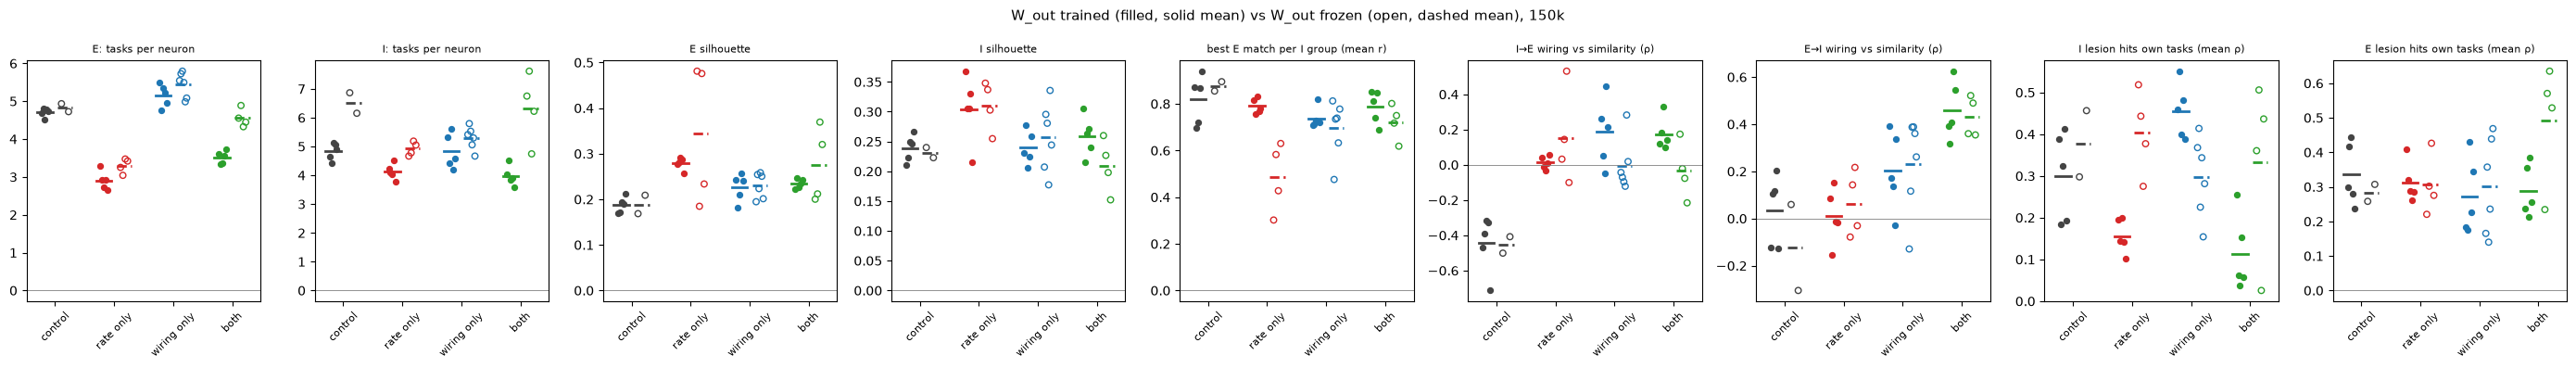

control        rate only        wiring only  \
                                  trained frozen   trained frozen     trained   
E: tasks per neuron                 4.701  4.829     2.901  3.296       5.153   
I: tasks per neuron                 4.829  6.510     4.134  4.921       4.831   
E silhouette                        0.187  0.189     0.279  0.344       0.226   
I silhouette                        0.239  0.231     0.305  0.311       0.240   
best E match per I group (mean r)   0.819  0.875     0.791  0.485       0.737   
I→E wiring vs similarity (ρ)       -0.443 -0.454     0.012  0.152       0.186   
E→I wiring vs similarity (ρ)        0.035 -0.123     0.012  0.063       0.202   
I lesion hits own tasks (mean ρ)    0.300  0.377     0.156  0.403       0.456   
E lesion hits own tasks (mean ρ)    0.336  0.283     0.312  0.306       0.272   

                                            both         
                                  frozen trained frozen  
E: tasks per neuron                5.438   3.522  4.554  
I: tasks per neuron                5.293   3.975  6.333  
E silhouette                       0.230   0.235  0.275  
I silhouette                       0.257   0.259  0.209  
best E match per I group (mean r)  0.695   0.788  0.722  
I→E wiring vs similarity (ρ)      -0.005   0.175 -0.035  
E→I wiring vs similarity (ρ)       0.231   0.458  0.431  
I lesion hits own tasks (mean ρ)   0.298   0.113  0.332  
E lesion hits own tasks (mean ρ)   0.301   0.289  0.492

In [6]:
TT = pd.read_csv("ei_modularity_150k_summary.csv")
TT["group"] = TT.point.map({"control": "control", "A3": "rate only", "B0": "wiring only", "C0": "both"})
metrics = ["E: tasks per neuron", "I: tasks per neuron", "E silhouette", "I silhouette",
           "best E match per I group (mean r)", "I→E wiring vs similarity (ρ)", "E→I wiring vs similarity (ρ)",
           "I lesion hits own tasks (mean ρ)", "E lesion hits own tasks (mean ρ)"]
gc = dict(zip(GROUPS, ["#444444", "#d62728", "#1f77b4", "#2ca02c"]))
fig, axes = plt.subplots(1, len(metrics), figsize=(3.1 * len(metrics), 4))
for ax, m in zip(axes, metrics):
    for i, gname in enumerate(GROUPS):
        a = TT[TT.group == gname][m].values
        b = TF[TF.group == gname][m].values
        ax.scatter(np.full(len(a), i - 0.17) + np.linspace(-0.06, 0.06, len(a)), a, color=gc[gname], s=18)
        ax.scatter(np.full(len(b), i + 0.17) + np.linspace(-0.06, 0.06, len(b)), b, facecolors="none",
                   edgecolors=gc[gname], s=22)
        ax.plot([i - 0.3, i - 0.04], [np.nanmean(a)] * 2, color=gc[gname], lw=2)
        ax.plot([i + 0.04, i + 0.3], [np.nanmean(b)] * 2, color=gc[gname], lw=2, ls="--")
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(GROUPS, rotation=45, fontsize=8)
    ax.set_title(m, fontsize=8)
fig.suptitle("W_out trained (filled, solid mean) vs W_out frozen (open, dashed mean), 150k", fontsize=11)
plt.tight_layout(); plt.show()

cmp = pd.concat([TT.assign(set="trained"), TF.assign(set="frozen")])
display(cmp.groupby(["group", "set"], sort=False)[metrics].mean().reindex(
    pd.MultiIndex.from_product([GROUPS, ["trained", "frozen"]])).round(3).T)

## 4. Do E groups just mirror the frozen readout?

For each E group: the mean cosine similarity between its members' (frozen) readout weight vectors (rows of W_out,
33 outputs). Network score: the size-weighted mean over groups, compared with the same groups after shuffling the
E labels 500 times (z). z ≈ 0: groups are unrelated to the readout; large z: E neurons that drive the same outputs
end up in the same task-variance group.

In [7]:
def readout_coherence(ckpt, R, n_shuffle=500, seed=0):
    with contextlib.redirect_stdout(io.StringIO()):
        model, _, _ = load_checkpoint(ckpt)
    Wo = model.w_out.detach().numpy()                          # (n_E, outputs)
    E = R["E"]
    V = Wo[E["units"]]
    V = V / np.linalg.norm(V, axis=1, keepdims=True)
    S = V @ V.T

    def score(lab):
        tot, n = 0.0, 0
        for c in np.unique(lab):
            m = np.flatnonzero(lab == c)
            if len(m) > 1:
                block = S[np.ix_(m, m)]
                tot += (block.sum() - len(m)) / (len(m) - 1)    # mean off-diagonal, times len(m)
                n += len(m)
        return tot / n

    obs = score(E["lab"])
    rng = np.random.default_rng(seed)
    null = np.array([score(rng.permutation(E["lab"])) for _ in range(n_shuffle)])
    return obs, (obs - null.mean()) / null.std()


rc = []
for grp, lab, run, p in FROZEN:
    for s in (0, 1):
        obs, z = readout_coherence(Z / run / p / f"seed_{s:02d}.pt", ALL[lab, s])
        rc.append({"group": grp, "point": lab, "seed": s, "within-group readout cosine": obs, "z vs shuffled": z})
RC = pd.DataFrame(rc)
display(RC.round(3))

,group,point,seed,within-group readout cosine,z vs shuffled
0,control,control,0,0.006,1.040
1,control,control,1,0.008,1.999
2,rate only,A0,0,0.015,5.486
3,rate only,A0,1,0.018,2.842
4,rate only,hi0,0,0.005,1.143
5,rate only,hi0,1,0.024,3.708
6,wiring only,B0,0,-0.002,-0.289
7,wiring only,B0,1,0.002,0.368
8,wiring only,hi9,0,0.001,0.335
9,wiring only,hi9,1,0.002,0.228


## 5. Details for one network per group (the better seed)

Same three figures as before: E and I task variance clustered separately; I group × E group task similarity and
wiring; specific drop when one E group or one I group is silenced alone.

### control

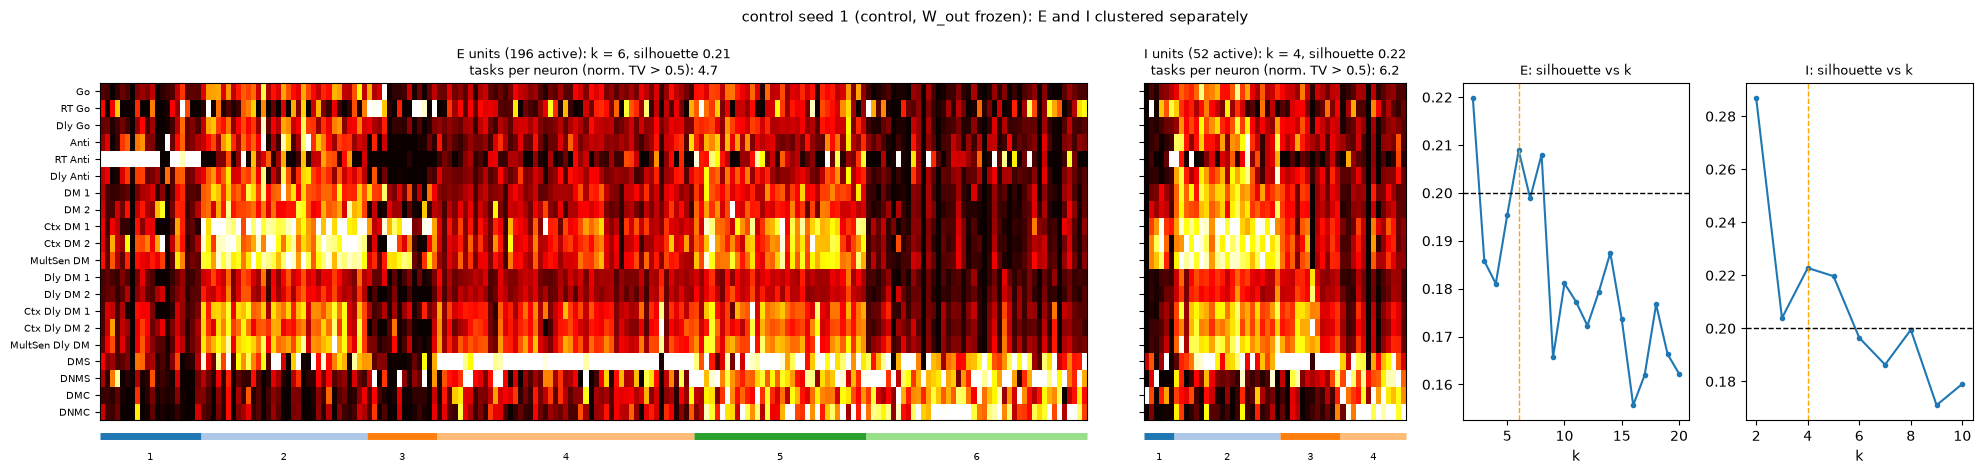

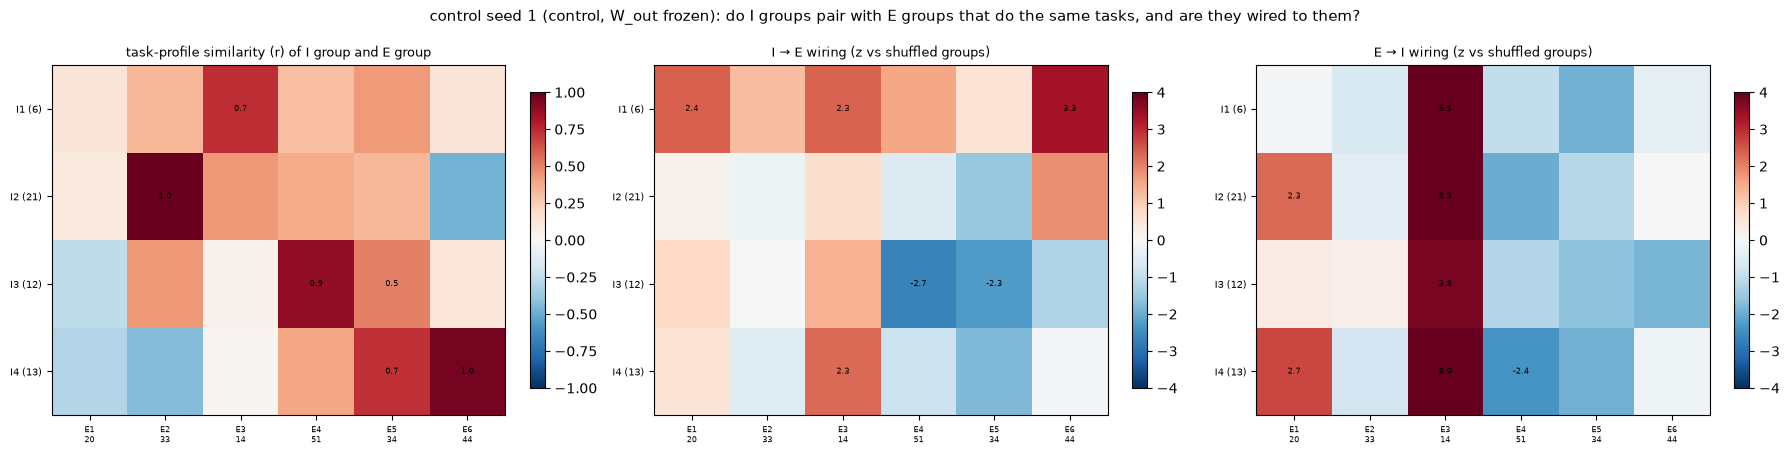

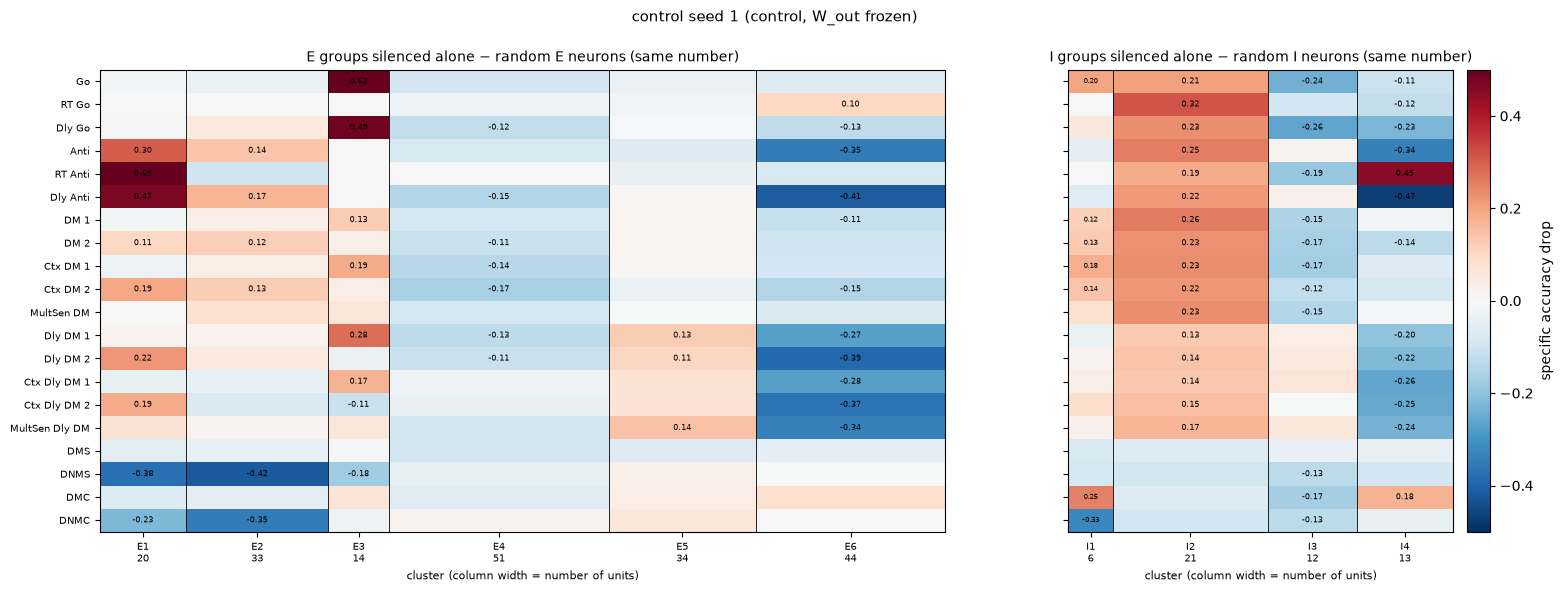

In [8]:
s = max((0, 1), key=lambda s: ACC["control", s])
plot_ei(ALL["control", s])

### A0

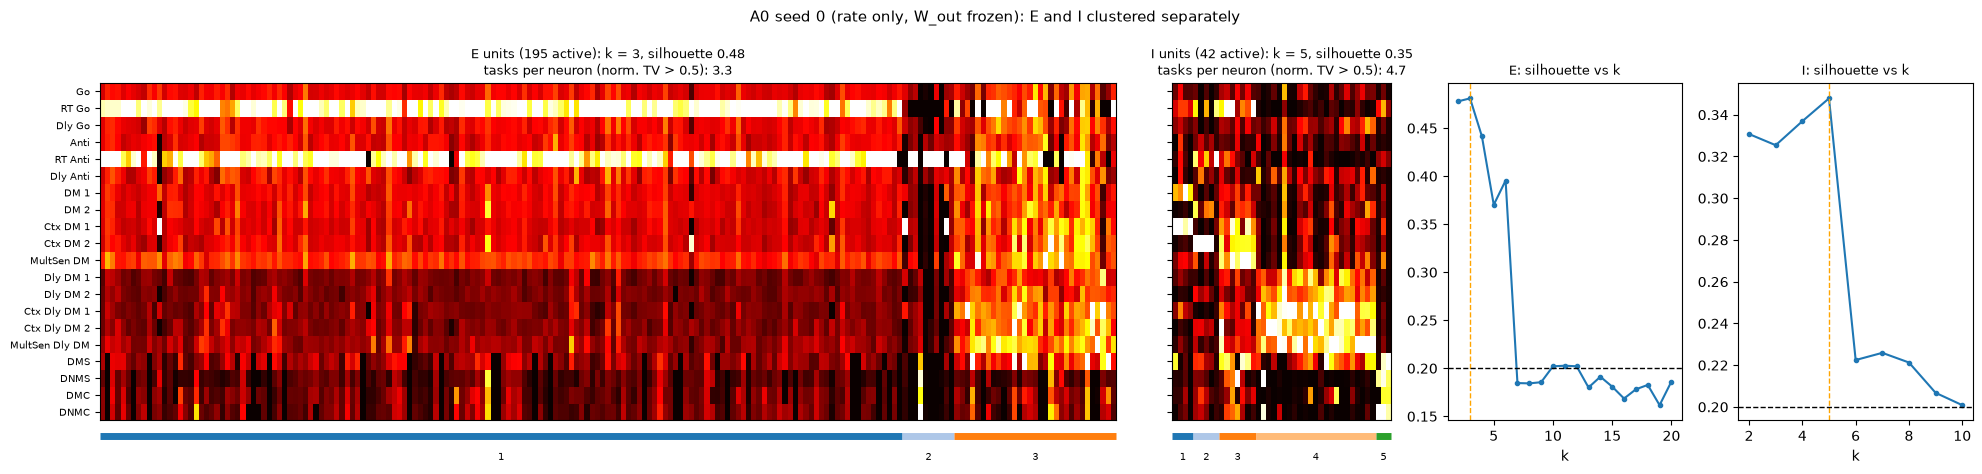

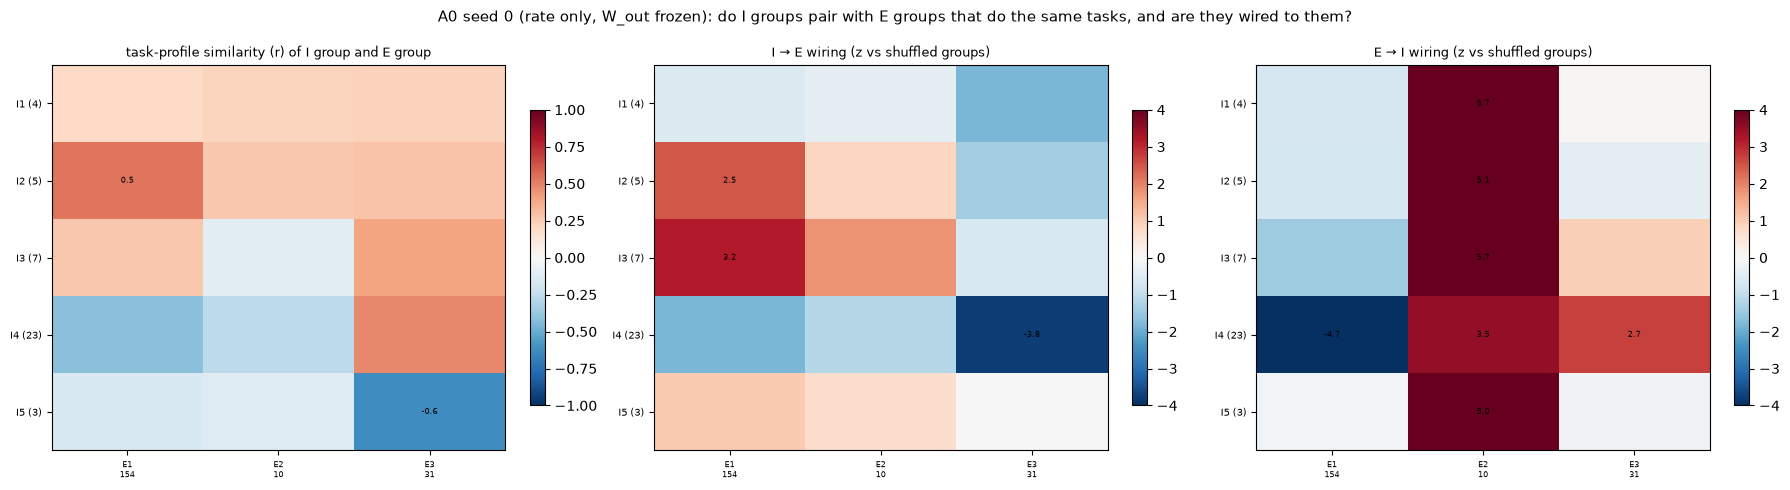

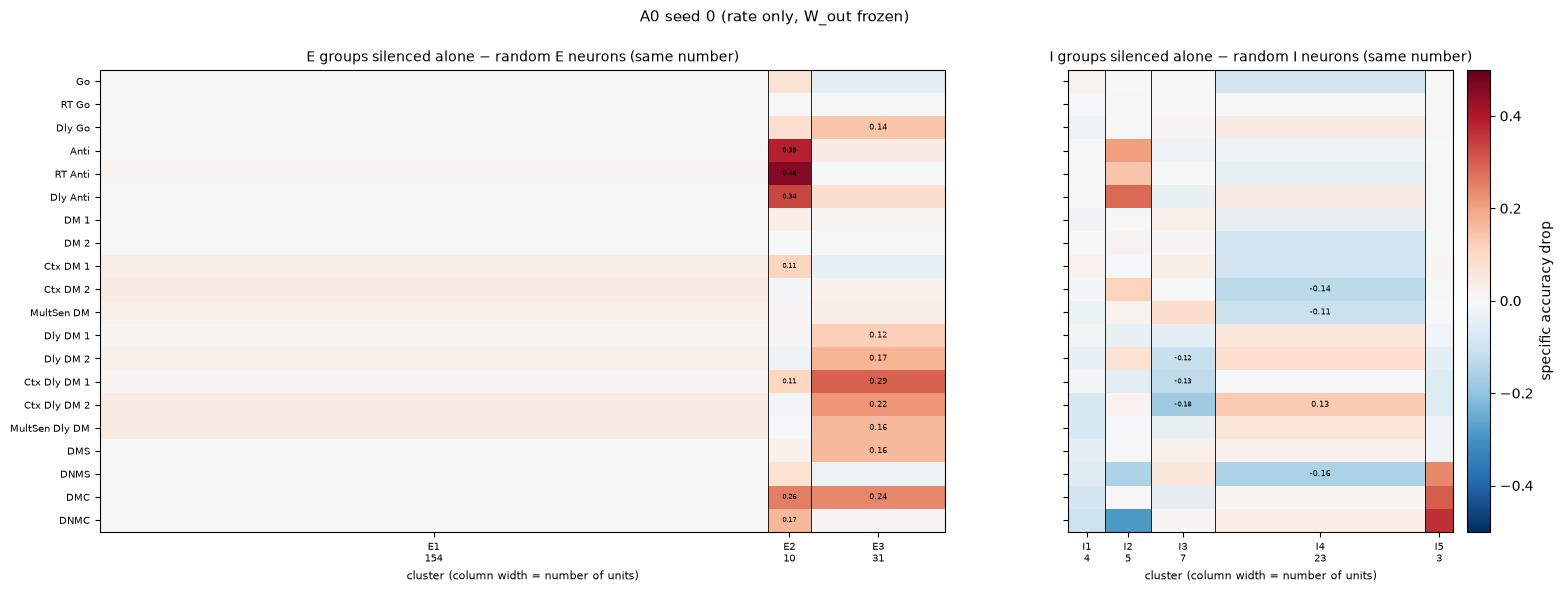

In [9]:
s = max((0, 1), key=lambda s: ACC["A0", s])
plot_ei(ALL["A0", s])

### B0

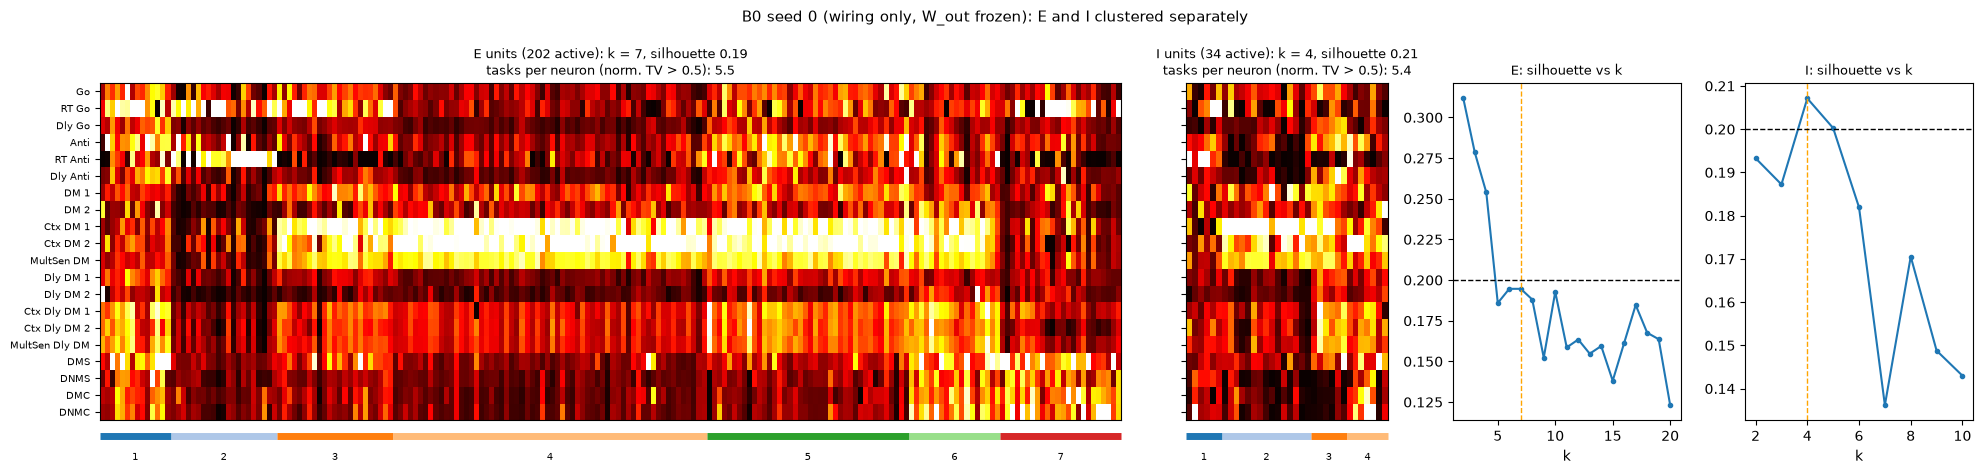

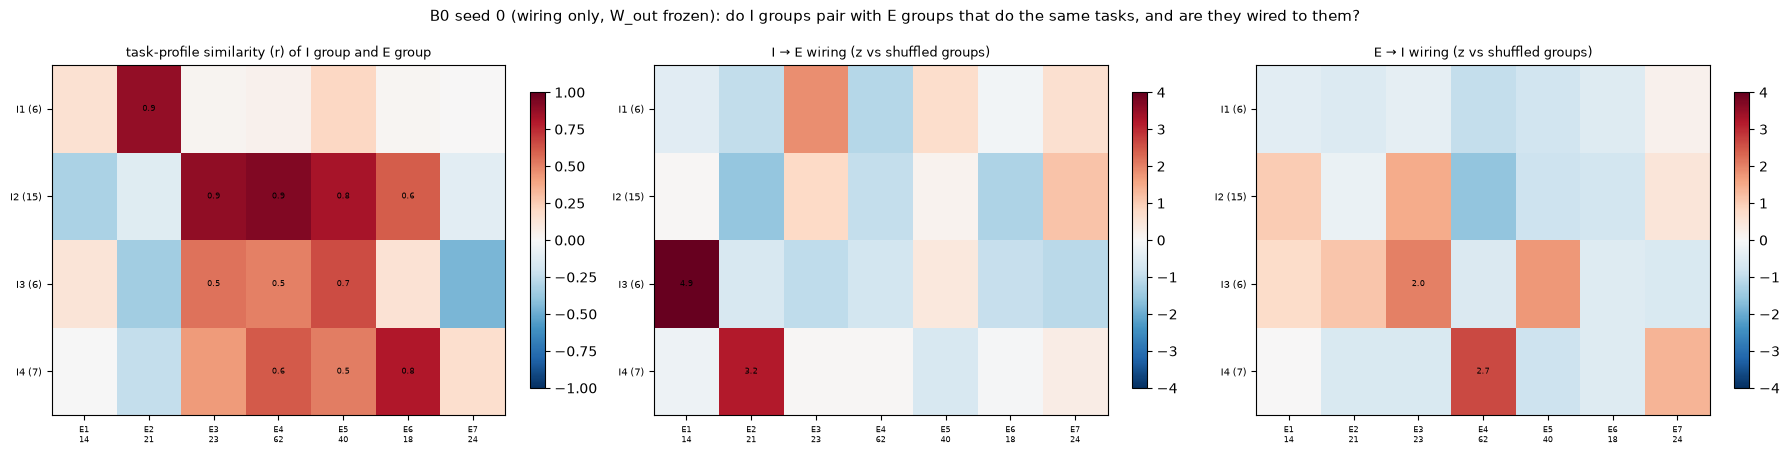

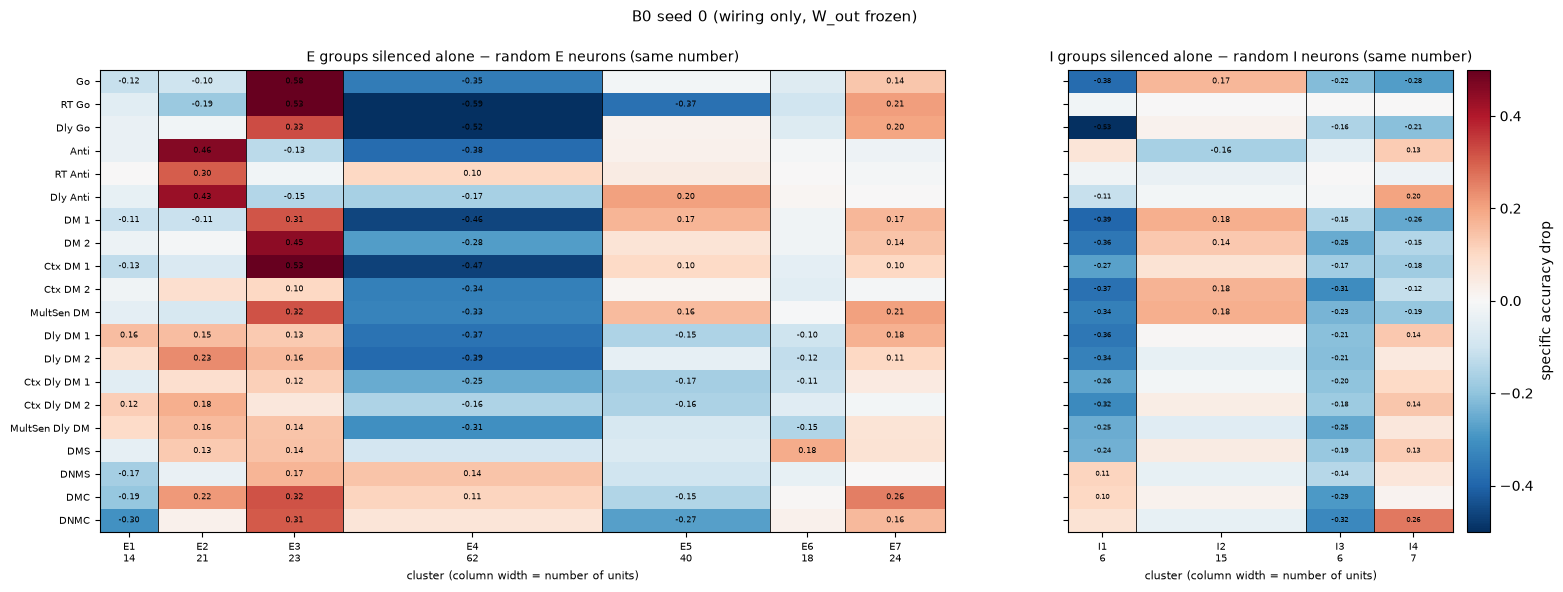

In [10]:
s = max((0, 1), key=lambda s: ACC["B0", s])
plot_ei(ALL["B0", s])

### hi5

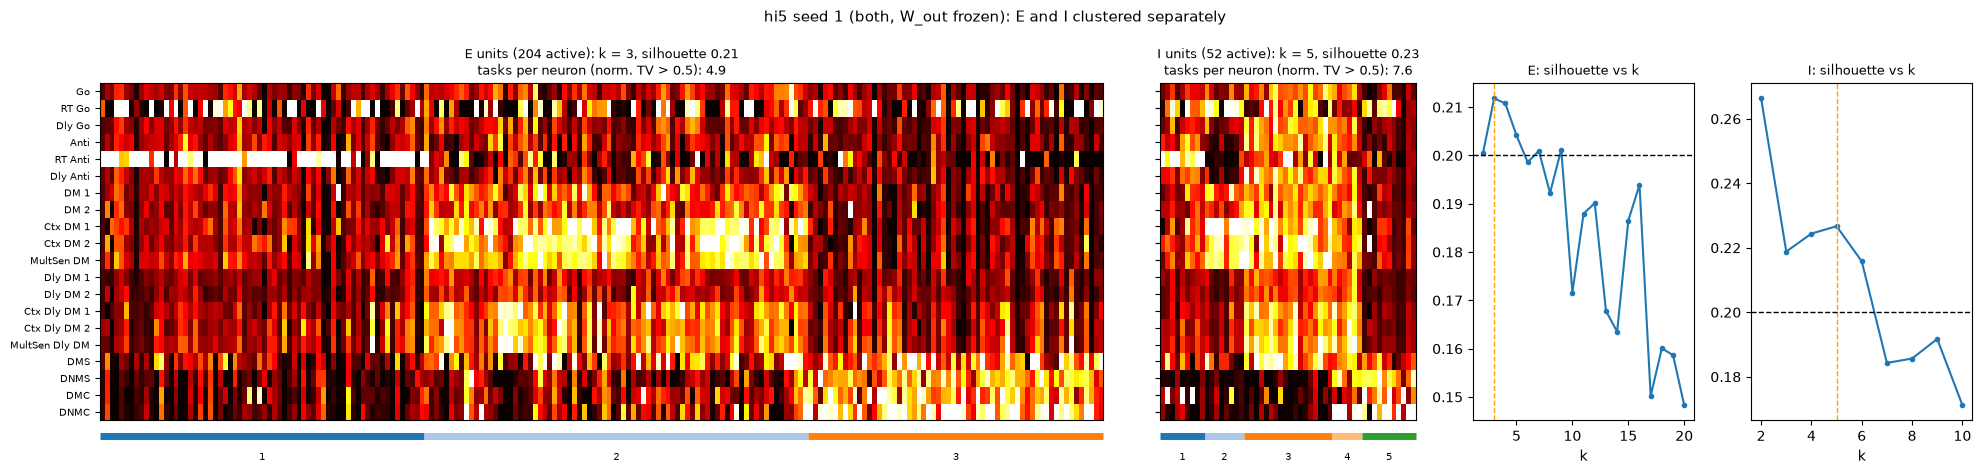

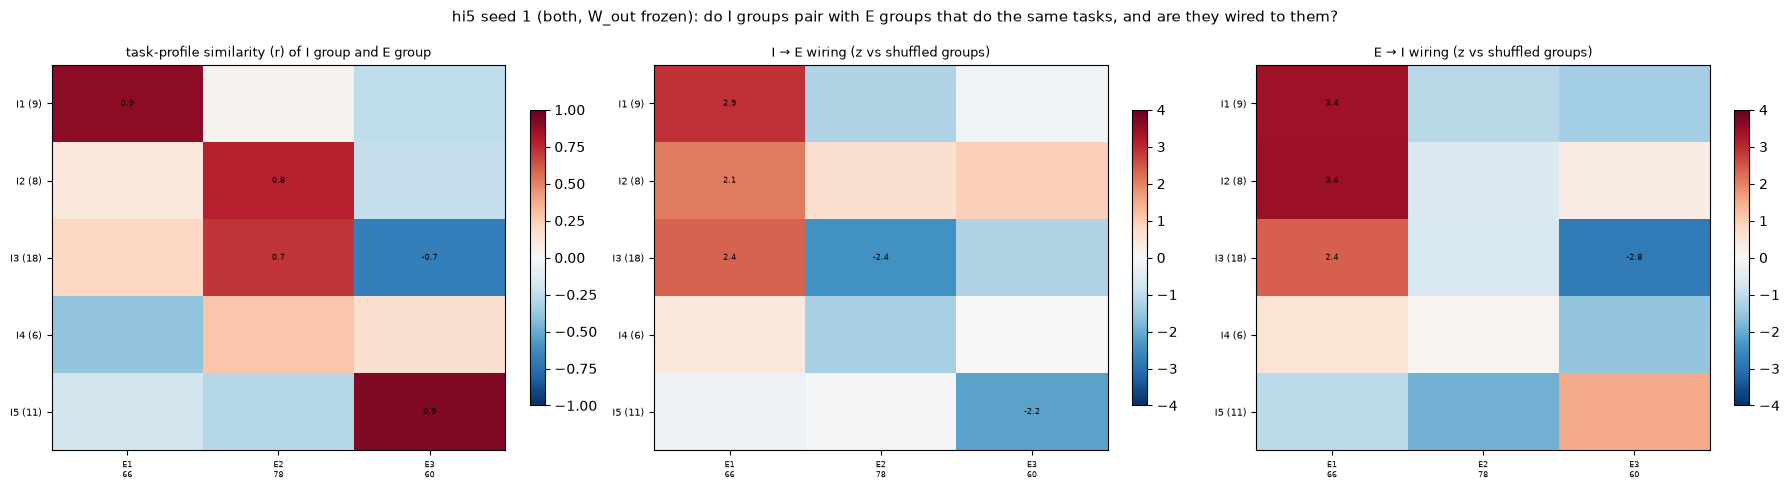

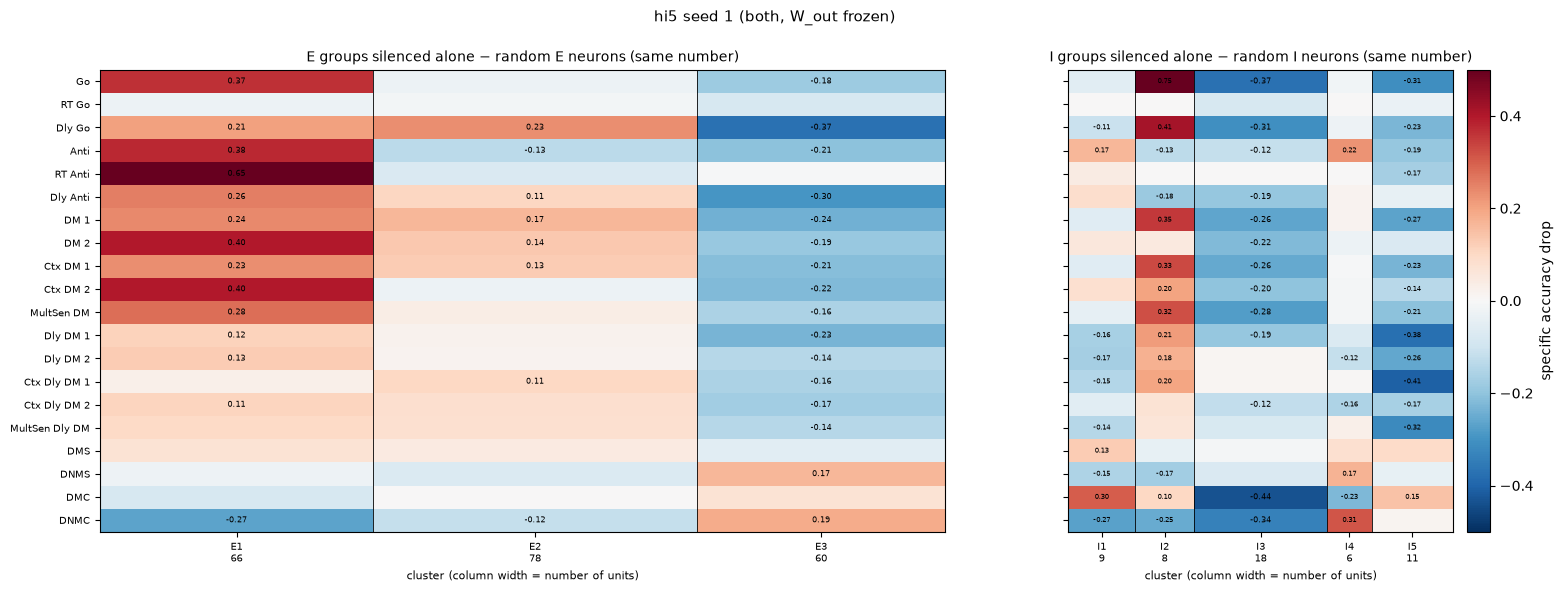

In [11]:
s = max((0, 1), key=lambda s: ACC["hi5", s])
plot_ei(ALL["hi5", s])

## 6. Reading it

Means per group (trained W_out: 5 seeds per point; frozen W_out: 2-6 networks per group):

| | control | | rate only | | wiring only | | both | |
|---|---|---|---|---|---|---|---|---|
| | trained | frozen | trained | frozen | trained | frozen | trained | frozen |
| min_task_acc | 0.96 | 0.94 | 0.85 | 0.75 | 0.87 | 0.72 | 0.88 | 0.71 |
| E / I tasks per neuron | 4.7 / 4.8 | 4.8 / **6.5** | 2.9 / 4.1 | 3.3 / 4.9 | 5.2 / 4.8 | 5.4 / 5.3 | 3.5 / 4.0 | 4.6 / **6.3** |
| best E match per I group | 0.82 | 0.87 | 0.79 | **0.49** | 0.74 | 0.70 | 0.79 | 0.72 |
| I→E wiring vs similarity (ρ) | **−0.44** | **−0.45** | 0.01 | 0.15 | 0.19 | −0.01 | 0.18 | −0.03 |
| E→I wiring vs similarity (ρ) | 0.04 | −0.12 | 0.01 | 0.06 | 0.20 | 0.23 | **0.46** | **0.43** |
| I lesion hits own tasks (ρ) | 0.30 | 0.38 | 0.16 | 0.40 | 0.46 | 0.30 | 0.11 | 0.33 |
| E groups mirror the readout (z) | | 1.0 / 2.0 | | **2.8-5.5** (3 of 4) | | ≈ 0 | | 1.0-2.9 |

* **The two clearest wiring results survive freezing W_out.**
  * control: I groups are wired to E groups of *other* tasks (I→E ρ −0.50 and −0.41, as with W_out trained, −0.44):
    inhibition between modules (type 3 direction).
  * "both": E→I wiring follows the tasks in all 4 frozen networks (+0.35 to +0.52), as with W_out trained (+0.46):
    the E side of the E+I modules is there either way.
* **What freezing changes:**
  * I neurons become broader (6.3-6.5 tasks per neuron in control and "both", vs ~4-5): more "shared inhibition"
    (type 1 flavour) on top.
  * The I→E half of the E+I pairing disappears in "wiring only" and "both" (ρ ≈ 0), so with a frozen readout the
    modules are wired one way (E→I) only.
  * **Rate only: part of the clustering is the readout.** In 3 of 4 rate-only networks, E neurons that share the same
    (random, fixed) readout weights end up in the same task-variance group (z 2.8-5.5); in the wiring-only networks
    this is absent (z ≈ 0). And the I groups no longer match E groups (0.49 vs 0.79). So the very high silhouettes
    seen earlier in frozen rate-limited networks (e.g. A0, 0.45) are partly a side effect of the fixed readout, not
    only of computation.
* Caveats: frozen budgets are 10-30× looser for "rate only" and "both" than A3 / C0 (tighter ones do not train with
  W_out frozen); 2 seeds per point; frozen networks reach lower accuracy (0.71-0.75 vs 0.85-0.88); r6w1 seed 0 fails
  the tasks (0.48).
